In [9]:
import os
import glob
import cv2
import numpy as np

# Trỏ thẳng vào thư mục con 'gray_enhanced' chứa toàn bộ ảnh đã tiền xử lý
folder_anh = r"C:\Users\ADMIN\Downloads\rice-quality-assessment\rice-quality-assessment-main\processed_dataset\2_batch_rice_images\gray_enhanced"

# Thư mục lưu kết quả phân đoạn
folder_ket_qua = r"C:\Users\ADMIN\Downloads\rice-quality-assessment\rice-quality-assessment-main\processed_dataset\3_segmented_rice_images"
os.makedirs(folder_ket_qua, exist_ok=True)

# Lấy toàn bộ file ảnh trong gray_enhanced
danh_sach_anh = sorted(glob.glob(os.path.join(folder_anh, "*.jpg")))
print(f"✔ Đã lấy đủ {len(danh_sach_anh)} file ảnh từ thư mục gray_enhanced!")

✔ Đã lấy đủ 31 file ảnh từ thư mục gray_enhanced!


In [17]:
def phan_doan_1_anh(img_goc, anh_da_loc_gauss):
    # 1. Bóc sạch vùng nền loang trắng bằng Top-Hat
    kernel_tophat = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
    anh_sach_nen = cv2.morphologyEx(anh_da_loc_gauss, cv2.MORPH_TOPHAT, kernel_tophat)
    
    # Tăng cường nhẹ độ tương phản cục bộ (CLAHE) trên ảnh đã bóc nền để hạt vùng lóa rõ lên
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    anh_tang_cuong = clahe.apply(anh_sach_nen)
    
    # 2. Chạy Otsu trên ảnh đã cân bằng cục bộ (bắt được cả hạt ở vùng lóa lẫn vùng tối)
    _, binary = cv2.threshold(anh_tang_cuong, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # Làm sạch nhiễu li ti
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
    closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel, iterations=1)
    
    # 3. Tìm tâm hạt (Giảm xuống 0.35 để không làm rớt hạt mảnh ở vùng lóa)
    dist = cv2.distanceTransform(closing, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist, 0.35 * dist.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)
    
    # 4. Đánh số vùng & Tách hạt dính (Watershed)
    sure_bg = cv2.dilate(closing, kernel, iterations=2)
    unknown = cv2.subtract(sure_bg, sure_fg)
    _, markers, _, _ = cv2.connectedComponentsWithStats(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0
    markers = cv2.watershed(cv2.cvtColor(closing, cv2.COLOR_GRAY2BGR), markers)
    
    # 5. Khoanh khung BBox, Gán ID & Cắt ROI từng hạt
    output_img = img_goc.copy()
    danh_sach_hat = []
    id_hat = 1
    
    for label in np.unique(markers):
        if label <= 1: continue
        mask_1_hat = np.uint8(markers == label) * 255
        contours, _ = cv2.findContours(mask_1_hat, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours: continue
        
        cnt = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(cnt)
        if area < 20 or area > 1500: continue
            
        x, y, w, h = cv2.boundingRect(cnt)
        roi_sach = cv2.bitwise_and(img_goc[y:y+h, x:x+w], img_goc[y:y+h, x:x+w], mask=mask_1_hat[y:y+h, x:x+w])
        
        cv2.drawContours(output_img, [cnt], -1, (0, 255, 0), 2)
        cv2.rectangle(output_img, (x, y), (x + w, y + h), (255, 0, 0), 1)
        cv2.putText(output_img, f"#{id_hat}", (x, max(y - 3, 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
        
        danh_sach_hat.append({"id": id_hat, "bbox": (x, y, w, h), "area": area, "roi_color": roi_sach, "roi_mask": mask_1_hat[y:y+h, x:x+w]})
        id_hat += 1
        
    return danh_sach_hat, output_img

✔ batch_rice_0001.jpg: tìm được 172 hạt
✔ batch_rice_0002.jpg: tìm được 184 hạt
✔ batch_rice_0003.jpg: tìm được 170 hạt
✔ batch_rice_0004.jpg: tìm được 168 hạt
✔ batch_rice_0005.jpg: tìm được 168 hạt
✔ batch_rice_0006.jpg: tìm được 190 hạt
✔ batch_rice_0007.jpg: tìm được 190 hạt
✔ batch_rice_0008.jpg: tìm được 162 hạt
✔ batch_rice_0009.jpg: tìm được 169 hạt
✔ batch_rice_0010.jpg: tìm được 187 hạt
✔ batch_rice_0011.jpg: tìm được 237 hạt
✔ batch_rice_0012.jpg: tìm được 176 hạt
✔ batch_rice_0013.jpg: tìm được 242 hạt
✔ batch_rice_0014.jpg: tìm được 230 hạt
✔ batch_rice_0015.jpg: tìm được 221 hạt
✔ batch_rice_0016.jpg: tìm được 238 hạt
✔ batch_rice_0017.jpg: tìm được 260 hạt
✔ batch_rice_0018.jpg: tìm được 242 hạt
✔ batch_rice_0019.jpg: tìm được 252 hạt
✔ batch_rice_0020.jpg: tìm được 251 hạt
✔ batch_rice_0021.jpg: tìm được 250 hạt
✔ batch_rice_0022.jpg: tìm được 257 hạt
✔ batch_rice_0023.jpg: tìm được 176 hạt
✔ batch_rice_0024.jpg: tìm được 247 hạt
✔ batch_rice_0025.jpg: tìm được 252 hạt


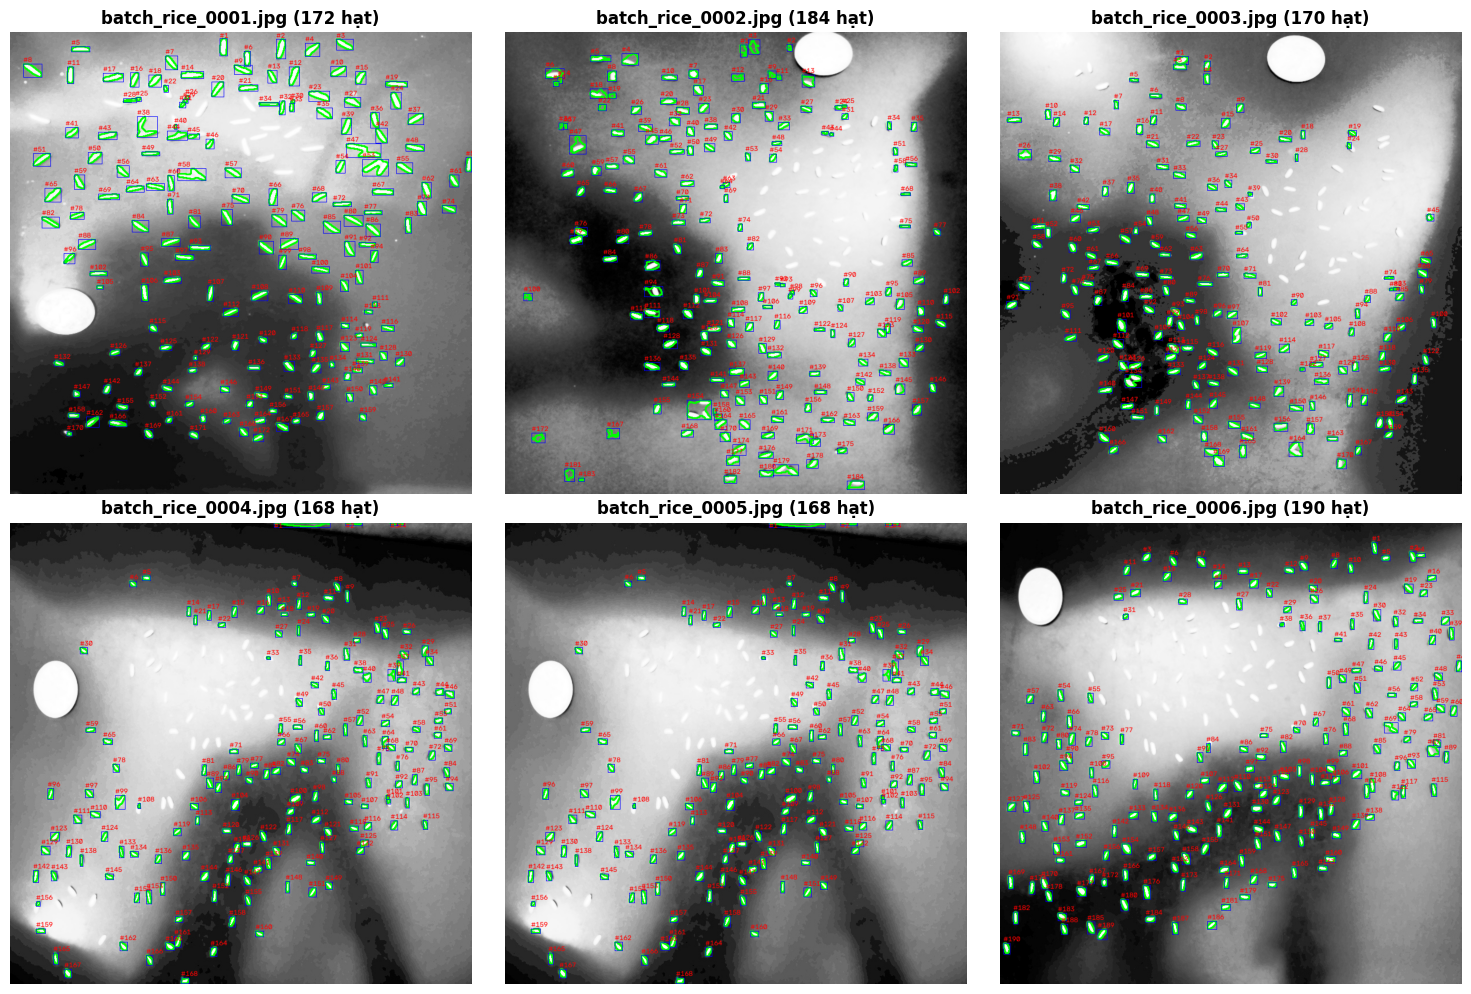

In [18]:
import matplotlib.pyplot as plt

tat_ca_du_lieu = {}
anh_hien_thi = []  # Lưu vài ảnh để vẽ lên màn hình Jupyter kiểm tra

for duong_dan in danh_sach_anh:
    ten_file = os.path.basename(duong_dan)
    img_goc = cv2.imread(duong_dan)
    if img_goc is None: continue

    # Ảnh trong gray_enhanced đã qua tiền xử lý của Thành viên 1
    anh_da_loc_gauss = cv2.cvtColor(img_goc, cv2.COLOR_BGR2GRAY)

    danh_sach_hat, anh_ket_qua = phan_doan_1_anh(img_goc, anh_da_loc_gauss)
    cv2.imwrite(os.path.join(folder_ket_qua, f"KQ_{ten_file}"), anh_ket_qua)
    
    tat_ca_du_lieu[ten_file] = danh_sach_hat
    if len(anh_hien_thi) < 6:  # Lấy 6 ảnh đầu tiên để show ngay bên dưới
        anh_hien_thi.append((ten_file, len(danh_sach_hat), anh_ket_qua))
        
    print(f"✔ {ten_file}: tìm được {len(danh_sach_hat)} hạt")

# --- HIỂN THỊ LƯỚI 6 ẢNH KẾT QUẢ NGAY TRONG JUPYTER ---
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for idx, (ten, so_hat, anh) in enumerate(anh_hien_thi):
    ax = axes[idx // 3, idx % 3]
    ax.imshow(cv2.cvtColor(anh, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{ten} ({so_hat} hạt)", fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()